# Turunan lima titik Pan-Tompkins: penurunan, pembuktian, dan fixed-point

Notebook ini menurunkan, membuktikan, dan memplot tahap turunan lima titik Pan-Tompkins,
persamaan (7), (8), dan (9) pada paper Pan dan Tompkins 1985 halaman 233:

$$ H(z) = \frac{1}{8T}\left(-z^{-2} - 2z^{-1} + 2z + z^{2}\right) $$

$$ \left|H(\omega T)\right| = \frac{1}{4T}\left[\sin(2\omega T) + 2\sin(\omega T)\right] $$

$$ y(nT) = \frac{1}{8T}\left[-x(nT - 2T) - 2x(nT - T) + 2x(nT + T) + x(nT + 2T)\right] $$

Setiap angka yang diklaim dihitung di sel tempat angka itu dicetak. Notebook ini pasangan dari
`low-pass-filter-equation.ipynb` dan `high-pass-filter-equation.ipynb`, yang membahas halaman 232
paper yang sama.

Isi notebook:

1. Persamaan beda dan fungsi alih, setup, dan koefisien tapis.
2. Notasi seluruh variabel.
3. Langkah dari bentuk terpusat ke bentuk kausal.
4. Fungsi alih dan tanggapan impuls.
5. Tanggapan amplitudo persamaan (8) beserta bentuk tertutupnya.
6. Titik puncak tanggapan, tunda dua sampel, dan kelinieran pita.
7. Kasus hitung tangan A, tanggapan impuls.
8. Kasus hitung tangan B, satu pulsa segitiga QRS.
9. Nol dan kutub.
10. Tanggapan magnitudo dengan penanda puncak dan penanda nol di frekuensi Nyquist.
11. Kasus sebelum dan sesudah pada sinyal QRS 250 Hz.
12. Fixed-point pada rekaman AFDB 04015 dengan konvensi terkunci.
13. Ringkasan seluruh angka terukur.

## 1. Persamaan beda dan fungsi alih

Paper Pan dan Tompkins 1985 menuliskan tahap turunan pada persamaan (7), (8), dan (9) halaman 233.
Persamaan (9) adalah persamaan bedanya, dan paper menuliskannya dalam bentuk terpusat sehingga
memakai sampel yang belum datang di kiri dan di kanan:

$$ y(nT) = \frac{1}{8T}\left[-x(nT - 2T) - 2x(nT - T) + 2x(nT + T) + x(nT + 2T)\right] $$

Empat koefisiennya adalah minus satu, minus dua, plus dua, dan plus satu, dengan pembagi delapan.
Fungsi alih yang setara, persamaan (7):

$$ H(z) = \frac{1}{8T}\left(-z^{-2} - 2z^{-1} + 2z + z^{2}\right) $$

Di bawah persamaan (9) paper menulis dua klaim: tanggapan frekuensinya hampir linear antara dc dan
30 Hz, dan tundanya dua sampel. Kedua klaim itu diuji di notebook ini, kelinieran di bagian 5 dan
tunda di bagian 6.

Syarat awal nol, sesuai implementasi di FPGA dan MCU saat start:

$$ x[n] = 0 \ \text{untuk} \ n < 0, \qquad y[n] = 0 \ \text{untuk} \ n < 0 $$

Sesudah indeksnya digeser dua sampel supaya kausal, koefisiennya menjadi satu, dua, nol, minus dua,
dan minus satu dengan pembagi delapan. Itulah vektor pembilang yang dipakai seluruh notebook.

In [1]:
# Tujuan: menyiapkan library, identitas interpreter, konstanta sampling, dan koefisien tahap turunan lima titik.
# Sel ini mencetak persamaan (7) dan (9) yang diimplementasikan, bentuk terpusat, bentuk kausal,
# vektor pembilang lima tap, dan koefisien tahap tetangga di rantai yang sama.

%matplotlib inline

import sys
import warnings
import pathlib
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import signal as sg

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True})
pd.set_option("display.width", 200)

FS_PAPER = 200.0   # sampling frequency paper Pan-Tompkins
FS_BOARD = 250.0   # sampling frequency board tim

print("tahap turunan lima titik, persamaan (7), (8), dan (9) paper Pan-Tompkins halaman 233")
print("  bentuk terpusat  y(nT) = 1/8T * [ -x(nT-2T) - 2x(nT-T) + 2x(nT+T) + x(nT+2T) ]")
print("  bentuk kausal    y[n]  = 1/8  * [ x[n] + 2x[n-1] + 0*x[n-2] - 2x[n-3] - x[n-4] ]")
print("  initial condition nol: x[n] = 0 dan y[n] = 0 untuk n < 0")
print("  paper: tunda dua sampel, dan tanggapan hampir linear antara dc dan 30 Hz")
print()

# Pembilang lima tap bentuk kausal. Template integer dibuat lebih dulu supaya pemeriksaan
# koefisien memakai aritmetika eksak, bukan pembulatan pecahan.
B_DER_INT = np.array([1, 2, 0, -2, -1], dtype=np.int64)
B_DER = B_DER_INT.astype(float) / 8.0
A_DER_INT = np.array([1], dtype=np.int64)
A_DER = A_DER_INT.astype(float)

# Pembilang bentuk terpusat, yaitu koefisien paper (7) tanpa penskalaan 1/T.
B_PUSAT_INT = np.array([-1, -2, 0, 2, 1], dtype=np.int64)

# Tahap tetangga di rantai, dipakai di bagian 11 dan 12. Low-pass koefisien 1 sampai 6,
# high-pass rekursif koefisien 32 dan 1 dan 1, lalu turunan ini.
HLP_INT = np.array([1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1], dtype=np.int64)
B_HP_INT = np.zeros(33, dtype=np.int64)
B_HP_INT[0] = -1
B_HP_INT[16] = 32
B_HP_INT[32] = 1
A_HP_INT = np.array([1, 1], dtype=np.int64)

# Direktori rekaman uji AFDB 04015 yang dipakai bagian 12.
DATA_DIR = pathlib.Path("/home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/derived")

HASIL = {}   # kumpulan angka terukur, dicetak sebagai tabel di bagian 13

print("interpreter :", sys.executable)
print("python      :", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__)
print("fs paper    :", FS_PAPER, "Hz | fs board :", FS_BOARD, "Hz")
print()
print("B_DER_INT lima tap                      :", B_DER_INT)
print("B_DER sesudah pembagian 8               :", B_DER)
print("A_DER_INT denominator                   :", A_DER_INT)
print("B_PUSAT_INT bentuk terpusat             :", B_PUSAT_INT)
print("jumlah koefisien B_DER_INT              :", int(B_DER_INT.sum()))
print("jumlah tap tak nol B_DER_INT            :", int(np.count_nonzero(B_DER_INT)))
print("indeks tak nol dan nilainya             :", np.flatnonzero(B_DER_INT),
      B_DER_INT[np.flatnonzero(B_DER_INT)])
print("HLP_INT low-pass, jumlah koefisiennya   :", int(HLP_INT.sum()))
print("A_HP_INT high-pass                      :", A_HP_INT)
print("B_HP_INT high-pass tak nol              :", np.flatnonzero(B_HP_INT),
      B_HP_INT[np.flatnonzero(B_HP_INT)])

assert B_DER_INT.size == 5, "pembilang harus lima tap"
assert int(np.count_nonzero(B_DER_INT)) == 4, "empat koefisien tak nol"
assert np.array_equal(np.flatnonzero(B_DER_INT), np.array([0, 1, 3, 4], dtype=np.int64))
assert np.array_equal(B_DER_INT[np.flatnonzero(B_DER_INT)], np.array([1, 2, -2, -1], dtype=np.int64))
assert int(B_DER_INT.sum()) == 0, "jumlah koefisien harus nol, yaitu penguatan nol di dc"
assert abs(float(B_DER.sum())) < 1e-15, "jumlah koefisien pecahan juga nol"
assert np.array_equal(np.sort(B_PUSAT_INT[B_PUSAT_INT != 0]), np.array([-2, -1, 1, 2], dtype=np.int64))
assert int(HLP_INT.sum()) == 36, "low-pass punya jumlah koefisien 36"

HASIL["jumlah tap pembilang"] = 5
HASIL["jumlah koefisien tak nol"] = 4
HASIL["jumlah koefisien pembilang"] = int(B_DER_INT.sum())
print("lolos: lima tap, empat koefisien tak nol 1, 2, minus 2, minus 1, jumlahnya nol")

tahap turunan lima titik, persamaan (7), (8), dan (9) paper Pan-Tompkins halaman 233
  bentuk terpusat  y(nT) = 1/8T * [ -x(nT-2T) - 2x(nT-T) + 2x(nT+T) + x(nT+2T) ]
  bentuk kausal    y[n]  = 1/8  * [ x[n] + 2x[n-1] + 0*x[n-2] - 2x[n-3] - x[n-4] ]
  initial condition nol: x[n] = 0 dan y[n] = 0 untuk n < 0
  paper: tunda dua sampel, dan tanggapan hampir linear antara dc dan 30 Hz

interpreter : /home/avivsabilalm/.venvs/afib-lite/bin/python
python      : 3.11.15 | numpy 2.4.6 | scipy 1.17.1 | pandas 2.3.3
fs paper    : 200.0 Hz | fs board : 250.0 Hz

B_DER_INT lima tap                      : [ 1  2  0 -2 -1]
B_DER sesudah pembagian 8               : [ 0.125  0.25   0.    -0.25  -0.125]
A_DER_INT denominator                   : [1]
B_PUSAT_INT bentuk terpusat             : [-1 -2  0  2  1]
jumlah koefisien B_DER_INT              : 0
jumlah tap tak nol B_DER_INT            : 4
indeks tak nol dan nilainya             : [0 1 3 4] [ 1  2 -2 -1]
HLP_INT low-pass, jumlah koefisiennya   : 36
A

## 2. Notasi

| Simbol | Arti |
|---|---|
| $n$ | indeks sample diskrit, bilangan bulat |
| $T$ | periode sampling, $T = 1/f_s$ |
| $f_s$ | sampling frequency dalam Hz, 200 Hz di paper dan 250 Hz di board tim |
| $x[n]$ | input pada sample $n$, yaitu sinyal setelah bandpass Pan-Tompkins |
| $y[n]$ | output pada sample $n$, yaitu sinyal setelah turunan lima titik |
| $z^{-1}$ | operator delay satu sample, memetakan $x[n]$ ke $x[n-1]$ |
| $H(z)$ | transfer function, $H(z) = Y(z)/X(z)$ |
| $\omega$ | frekuensi sudut digital, $\omega = 2 \pi f / f_s$ dalam rad/sample |
| $u$ | singkatan $\omega T$, yaitu frekuensi ternormalisasi dalam radian |
| $\delta[n]$ | unit impulse, $\delta[0] = 1$ dan $\delta[n] = 0$ untuk $n \neq 0$ |
| $h[n]$ | impulse response, yaitu output saat input $x[n] = \delta[n]$ |

Dua besaran turunan yang dipakai berulang:

- Nol: akar pembilang $1 + 2z^{-1} - 2z^{-3} - z^{-4}$, seluruhnya berada di lingkaran satuan dan
  dibahas di bagian 9.
- Kutub: tidak ada, karena denominatornya $A(z) = 1$. Tahap ini FIR, jadi keluarannya selalu
  berhingga dan tidak ada umpan balik yang bisa menyimpang.

## 3. Langkah 1. Dari bentuk terpusat ke bentuk kausal

Persamaan (9) memakai $x(nT + T)$ dan $x(nT + 2T)$, yaitu sampel yang belum datang. Bentuk itu tidak
bisa langsung dipasang di perangkat keras yang bekerja sample per sample. Indeksnya digeser dua
langkah dengan memisalkan $m = n + 2$, sehingga $n = m - 2$ dan tiap argumennya berubah seperti ini:

$$ x(nT - 2T) \rightarrow x[m - 4], \quad x(nT - T) \rightarrow x[m - 3], \quad x(nT + T) \rightarrow x[m - 1], \quad x(nT + 2T) \rightarrow x[m] $$

Substitusi ke persamaan (9):

$$ y[m] = \frac{1}{8T}\left[-x[m-4] - 2x[m-3] + 2x[m-1] + x[m]\right] $$

Urutkan mulai dari sampel terbaru, dan tulis kembali indeksnya sebagai $n$:

$$ y[n] = \frac{1}{8T}\Big(x[n] + 2x[n-1] - 2x[n-3] - x[n-4]\Big) $$

Dalam implementasi perangkat keras faktor $T$ tidak dibawa, karena hanya mengubah skala waktu dan
bukan bentuk tanggapan. Yang tertinggal adalah koefisien satu, dua, nol, minus dua, dan minus satu
dengan pembagian delapan. Pergeseran indeks itu menambah tunda dua sampel pada keluarannya, dan angka
dua sampel itulah yang ditulis paper di bawah persamaan (9).

In [2]:
# Tujuan: membuktikan secara numerik bahwa bentuk terpusat dan bentuk kausal memberi keluaran identik,
# dengan bentuk kausal tertunda dua sampel. Karena inputnya larik bilangan bulat, kesamaannya eksak.
# Sel ini mencetak keluaran kedua bentuk pada sampel awal, galat maksimumnya, dan galat jalur pecahan.

def terpusat_int(x_in):
    """bentuk paper (9) apa adanya, memakai sampel yang belum datang, dalam bilangan bulat"""
    xv = lambda i: 0 if i < 0 or i >= len(x_in) else int(x_in[i])
    return np.array([-xv(n - 2) - 2 * xv(n - 1) + 2 * xv(n + 1) + xv(n + 2)
                     for n in range(len(x_in))], dtype=np.int64)


def kausal_int(x_in):
    """bentuk hasil geser dua sampel, x[n] + 2x[n-1] - 2x[n-3] - x[n-4], dalam bilangan bulat"""
    xv = lambda i: 0 if i < 0 or i >= len(x_in) else int(x_in[i])
    return np.array([xv(n) + 2 * xv(n - 1) - 2 * xv(n - 3) - xv(n - 4)
                     for n in range(len(x_in))], dtype=np.int64)


rng_l1 = np.random.default_rng(11)
x_l1_int = rng_l1.integers(-60, 61, 256).astype(np.int64)   # aritmetika eksak
x_l1_float = rng_l1.normal(0.0, 1.0, 256)                   # aritmetika pembulatan

y_pusat_int = terpusat_int(x_l1_int)
y_kaus_int = kausal_int(x_l1_int)

# Bentuk kausal tertunda dua sampel terhadap bentuk terpusat, jadi yang dibandingkan y_kaus[2:] lawan y_pusat[:-2].
sama_geser = bool(np.array_equal(y_kaus_int[2:], y_pusat_int[:-2]))
galat_geser = int(np.max(np.abs(y_kaus_int[2:] - y_pusat_int[:-2])))

# Jalur pecahan memakai input yang sama supaya tidak ada perbedaan yang datang dari kuantisasi input.
# lfilter memakai urutan operasi berbeda, jadi dibandingkan setelah pembulatan keluar.
y_lfilter_8 = sg.lfilter(B_DER, A_DER, x_l1_int.astype(float)) * 8.0
y_lfilter_bulat = np.rint(y_lfilter_8).astype(np.int64)
sama_lfilter = bool(np.array_equal(y_kaus_int, y_lfilter_bulat))
galat_lfilter = int(np.max(np.abs(y_kaus_int - y_lfilter_bulat)))


def terpusat_float(x_in):
    """bentuk paper (9) pada input pecahan, dibagi delapan supaya satuannya sama dengan keluaran"""
    xv = lambda i: 0.0 if i < 0 or i >= len(x_in) else float(x_in[i])
    return np.array([-xv(n - 2) - 2 * xv(n - 1) + 2 * xv(n + 1) + xv(n + 2)
                     for n in range(len(x_in))]) / 8.0


# Pada input kontinu kesamaannya tidak eksak, jadi hanya diukur dengan toleransi.
y_pusat_float = terpusat_float(x_l1_float)
y_lfilter_float = sg.lfilter(B_DER, A_DER, x_l1_float)
galat_mesin = float(np.max(np.abs(y_lfilter_float[2:] - y_pusat_float[:-2])))

print("jumlah sampel uji                        :", x_l1_int.size)
print("rentang input integer                    :", int(x_l1_int.min()), "sampai", int(x_l1_int.max()))
print("bentuk terpusat, pembilang n = 0..7      :", y_pusat_int[:8])
print("bentuk kausal,   pembilang n = 2..9      :", y_kaus_int[2:10])
print("kedua bentuk identik sesudah tunda 2     :", sama_geser)
print("galat maksimum integer                   :", galat_geser)
print("keluaran lfilter dikali 8, n = 2..9      :", y_lfilter_bulat[2:10])
print("jalur lfilter identik dengan bentuk kausal:", sama_lfilter)
print("galat maksimum jalur lfilter             :", galat_lfilter)
print("galat maksimum bentuk terpusat lawan lfilter pada input pecahan :", galat_mesin)
print("catatan: galat pada jalur pecahan hanya berasal dari urutan penjumlahan yang tidak asosiatif,")
print("sehingga klaim identitas dibuktikan eksak pada jalur integer dan jalur pecahan diukur dengan toleransi")

assert sama_geser, "bentuk kausal harus sama eksak dengan bentuk terpusat yang ditunda dua sampel"
assert galat_geser == 0, "galat integer harus nol"
assert sama_lfilter and galat_lfilter == 0, "jalur lfilter harus sama eksak setelah dibulatkan"
assert galat_mesin < 1e-12, "galat jalur pecahan harus di bawah toleransi"
HASIL["galat terpusat lawan kausal integer"] = galat_geser
HASIL["galat jalur lfilter"] = galat_lfilter
HASIL["galat jalur pecahan"] = galat_mesin
print("lolos: pergeseran dua sampel tidak mengubah nilai, hanya menambah tunda")

jumlah sampel uji                        : 256
rentang input integer                    : -60 sampai 60
bentuk terpusat, pembilang n = 0..7      : [ -54  160  145    7   14  -27 -151 -111]
bentuk kausal,   pembilang n = 2..9      : [ -54  160  145    7   14  -27 -151 -111]
kedua bentuk identik sesudah tunda 2     : True
galat maksimum integer                   : 0
keluaran lfilter dikali 8, n = 2..9      : [ -54  160  145    7   14  -27 -151 -111]
jalur lfilter identik dengan bentuk kausal: True
galat maksimum jalur lfilter             : 0
galat maksimum bentuk terpusat lawan lfilter pada input pecahan : 0.0
catatan: galat pada jalur pecahan hanya berasal dari urutan penjumlahan yang tidak asosiatif,
sehingga klaim identitas dibuktikan eksak pada jalur integer dan jalur pecahan diukur dengan toleransi
lolos: pergeseran dua sampel tidak mengubah nilai, hanya menambah tunda


## 4. Langkah 2. Fungsi alih dan tanggapan impuls

Transformasi z pada bentuk kausal, dengan syarat awal nol:

$$ Y(z) = \frac{1}{8}\left(X(z) + 2z^{-1}X(z) - 2z^{-3}X(z) - z^{-4}X(z)\right) $$

$$ H(z) = \frac{Y(z)}{X(z)} = \frac{1}{8}\left(1 + 2z^{-1} - 2z^{-3} - z^{-4}\right) = \frac{B(z)}{A(z)} $$

dengan $B(z) = \frac{1}{8}\left(1 + 2z^{-1} - 2z^{-3} - z^{-4}\right)$ dan $A(z) = 1$. Dua vektor itu
yang dipakai `lfilter`, dan karena $A(z) = 1$ tahap ini FIR murni.

Tanggapan impulsnya adalah koefisiennya sendiri:

$$ h[n] = \frac{1}{8}\Big(\delta[n] + 2\delta[n-1] - 2\delta[n-3] - \delta[n-4]\Big) $$

Jadi $h = \frac{1}{8}\left(1, \ 2, \ 0, \ -2, \ -1\right)$, yaitu lima nilai, dan jumlahnya nol.
Jumlah nol itulah sebabnya penguatan DC-nya nol: turunan tidak melihat nilai rata rata, hanya
perubahannya. Tundanya dua sampel karena puncak koefisien ada di indeks dua, dan kernelnya
antisimetris terhadap indeks itu.

In [3]:
# Tujuan: membuktikan bahwa tanggapan impuls sama dengan vektor koefisien pembilang, secara eksak pada integer,
# dan bahwa jumlah tanggapan impulsnya nol sehingga penguatan DC-nya nol.
# Sel ini mencetak tanggapan impuls terukur, jumlahnya, dan galat terhadap vektor koefisien.

# Impuls dinaikkan ke amplitudo 8 supaya keluarannya bilangan bulat dan kesamaannya bisa diperiksa eksak.
N_IMP = 12
imp8 = np.zeros(N_IMP)
imp8[0] = 8.0
h_numerik = sg.lfilter(B_DER, A_DER, imp8)           # nilai pecahan
h_numerik_int = np.rint(h_numerik).astype(np.int64)  # nilai bulat, sama dengan koefisien mentah

h_tutup = np.zeros(N_IMP, dtype=np.int64)
h_tutup[:5] = B_DER_INT                              # 1, 2, 0, -2, -1

sama_impuls = bool(np.array_equal(h_numerik_int, h_tutup))
galat_impuls = int(np.max(np.abs(h_numerik_int - h_tutup)))
jumlah_h = int(h_tutup.sum())
indeks_h = np.flatnonzero(h_tutup)
panjang_dukungan = int(indeks_h[-1] - indeks_h[0] + 1)

print("impuls amplitudo 8, panjang uji          :", N_IMP)
print("tanggapan impuls dikali 8, n = 0..7      :", h_numerik_int[:8])
print("bentuk tertutup h[n] dikali 8, n = 0..7   :", h_tutup[:8])
print("kedua jalur identik (array_equal)        :", sama_impuls)
print("galat maksimum                           :", galat_impuls)
print("jumlah tanggapan impuls, yaitu penguatan dc dari koefisien mentah :", jumlah_h)
print("indeks koefisien tak nol                 :", indeks_h)
print("panjang dukungan, yaitu jumlah tap       :", panjang_dukungan)
print("indeks pusat kernel antisimetris          : 2, dan itulah asal tundanya dua sampel")
print("nilai mutlak koefisien terbesar di indeks :", int(np.argmax(np.abs(h_tutup))))
print("antisimetris terhadap indeks 2           :", bool(h_tutup[2] == 0
      and h_tutup[1] == -h_tutup[3] and h_tutup[0] == -h_tutup[4]))
print("tanggapan impuls pecahan                 :", h_numerik[:5])

assert sama_impuls and galat_impuls == 0, "tanggapan impuls harus sama eksak dengan vektor koefisien"
assert jumlah_h == 0, "jumlah tanggapan impuls harus nol"
assert panjang_dukungan == 5, "dukungan tanggapan impuls harus lima tap"
assert h_tutup[1] == -h_tutup[3] and h_tutup[0] == -h_tutup[4], "kernel harus antisimetris"
assert abs(float(np.sum(h_numerik))) < 1e-15, "jumlah pecahan juga nol"
HASIL["jumlah tanggapan impuls"] = jumlah_h
HASIL["panjang dukungan impuls"] = panjang_dukungan
HASIL["tunda sampel"] = 2
print("lolos: tanggapan impuls sama eksak dengan koefisien dan jumlahnya nol")

impuls amplitudo 8, panjang uji          : 12
tanggapan impuls dikali 8, n = 0..7      : [ 1  2  0 -2 -1  0  0  0]
bentuk tertutup h[n] dikali 8, n = 0..7   : [ 1  2  0 -2 -1  0  0  0]
kedua jalur identik (array_equal)        : True
galat maksimum                           : 0
jumlah tanggapan impuls, yaitu penguatan dc dari koefisien mentah : 0
indeks koefisien tak nol                 : [0 1 3 4]
panjang dukungan, yaitu jumlah tap       : 5
indeks pusat kernel antisimetris          : 2, dan itulah asal tundanya dua sampel
nilai mutlak koefisien terbesar di indeks : 1
antisimetris terhadap indeks 2           : True
tanggapan impuls pecahan                 : [ 1.  2.  0. -2. -1.]
lolos: tanggapan impuls sama eksak dengan koefisien dan jumlahnya nol


## 5. Langkah 3. Tanggapan amplitudo, persamaan (8)

Substitusi $z = e^{ju}$ dengan $u = \omega T$. Faktorkan bentuk terpusat supaya simetrinya terlihat,
dan satu suku fase keluar:

$$ B(e^{ju}) = \frac{1}{8}e^{-j2u}\left(e^{j2u} + 2e^{ju} - 2e^{-ju} - e^{-j2u}\right) = \frac{1}{8}e^{-j2u}\Big(4j\sin(u) + 2j\sin(2u)\Big) $$

Modulusnya, dengan $e^{-j2u}$ yang modulusnya satu:

$$ \left|H(e^{ju})\right| = \frac{1}{8}\left|4\sin(u) + 2\sin(2u)\right| = \frac{1}{4}\Big(\sin(2u) + 2\sin(u)\Big) $$

Suku di dalam tanda kurung tidak pernah negatif untuk $0 \le u \le \pi$, karena

$$ \sin(2u) + 2\sin(u) = 2\sin(u)\Big(1 + \cos(u)\Big) $$

dan kedua faktornya tidak negatif di rentang itu. Jadi tanda harga mutlak boleh dibuka. Kembalikan
faktor $\frac{1}{T}$ milik paper:

$$ \left|H(\omega T)\right| = \frac{1}{4T}\left[\sin(2\omega T) + 2\sin(\omega T)\right] $$

Itulah persamaan (8). Karena $u = \omega T = 2\pi f / f_s$, bentuk itu hanya bergantung pada rasio
frekuensi terhadap laju sampling. Untuk perhitungan numerik dipakai bentuk setara yang tidak
mengandung pengurangan dua suku yang hampir nol:

$$ \sin(2u) + 2\sin(u) = 4\sin\left(\frac{u}{2}\right)\cos^{3}\left(\frac{u}{2}\right) $$

Di dekat frekuensi Nyquist kedua suku pada bentuk pertama saling menghapus, sehingga ketelitian
relatifnya turun. Bentuk kosinus tidak punya masalah itu, dan itu sebabnya kedua bentuk dibandingkan
terpisah di sel berikut.

In [4]:
# Tujuan: membuktikan rumus amplitudo persamaan (8) terhadap freqz pada grid frekuensi padat, dan mencetak
# respons di 5 Hz dan 15 Hz, yaitu pita QRS yang menjadi target AFIB-LITE.
# Sel ini mencetak galat relatif maksimum, galat absolut maksimum, dan nilai |H| di beberapa frekuensi.

u_padat = np.linspace(1e-9, np.pi - 1e-9, 200001)
f_padat = u_padat * FS_BOARD / (2.0 * np.pi)

H_freqz = np.abs(sg.freqz(B_DER, A_DER, worN=u_padat)[1])                       # per sampel
H_paper = (1.0 / (4.0 / FS_BOARD)) * (np.sin(2.0 * u_padat) + 2.0 * np.sin(u_padat)) / FS_BOARD
H_kos = 2.0 * np.sin(u_padat / 2.0) * np.cos(u_padat / 2.0) ** 3                # bentuk kosinus

# Di satu titik terakhir sebelum Nyquist kedua sinus pada persamaan (8) hampir nol, sehingga galat
# relatifnya tumbuh dari penghapusan angka. Karena itu galat relatif diukur pada pita yang berguna,
# sedangkan galat absolut diukur pada seluruh grid.
muka = f_padat <= FS_BOARD / 2.0 - 1.0
galat_rel_paper = float(np.max(np.abs(H_freqz[muka] - H_paper[muka]) / H_freqz[muka]))
galat_rel_kos = float(np.max(np.abs(H_freqz[muka] - H_kos[muka]) / H_kos[muka]))
galat_abs_paper = float(np.max(np.abs(H_freqz - H_paper)))
galat_abs_kos = float(np.max(np.abs(H_freqz - H_kos)))
H_dc = float(np.abs(sg.freqz(B_DER, A_DER, worN=[0.0])[1][0]))
B_nyq = float(abs(np.polyval(np.flipud(B_DER), -1.0)))


def respon(f_hz):
    """|H| per sampel dan |H| persamaan (8) pada satu frekuensi"""
    uu = 2.0 * np.pi * f_hz / FS_BOARD
    hn = float(np.abs(sg.freqz(B_DER, A_DER, worN=[uu])[1][0]))
    hp = (1.0 / (4.0 / FS_BOARD)) * (np.sin(2.0 * uu) + 2.0 * np.sin(uu))
    return hn, hp


print("rumus amplitudo persamaan (8) paper: |H(wT)| = 1/(4T) * [ sin(2wT) + 2 sin(wT) ]")
print("bentuk kosinus setara              : |H| = 2 sin(u/2) cos^3(u/2), per sampel")
print("jumlah titik grid frekuensi        :", u_padat.size, "dari 0 sampai hampir pi")
print("galat relatif maksimum persamaan (8), f dari 0,1 Hz sampai 1 Hz sebelum Nyquist :", galat_rel_paper)
print("galat relatif maksimum bentuk kosinus pada rentang yang sama                     :", galat_rel_kos)
print("galat absolut maksimum persamaan (8) pada seluruh grid                          :", galat_abs_paper)
print("galat absolut maksimum bentuk kosinus pada seluruh grid                         :", galat_abs_kos)
print()
print("|H| di dc, dari freqz              :", H_dc)
print("|H| di frekuensi Nyquist, polval   :", B_nyq)
print()
for ff in (5.0, 15.0, 20.0, 30.0, 41.666666666666664):
    hn, hp = respon(ff)
    print("f = %8.4f Hz | |H| per sampel %.10f | |H| persamaan (8) %.6f | rasio %.6f"
          % (ff, hn, hp, hp / hn))
print()
print("catatan terukur: rasio |H| persamaan (8) terhadap |H| per sampel tepat sama dengan fs =",
      FS_BOARD, "karena persamaan (8) membawa faktor 1/T")
print("catatan terukur: antara dc dan 30 Hz kurvanya naik mulus tanpa puncak dan tanpa takik, jadi klaim")
print("paper tentang tanggapan yang hampir linear antara dc dan 30 Hz sejalan dengan angka di atas")

assert galat_rel_paper < 1e-10, "persamaan (8) harus cocok dengan freqz"
assert galat_rel_kos < 1e-10, "bentuk kosinus harus cocok dengan freqz"
assert galat_abs_paper < 1e-12 and galat_abs_kos < 1e-12, "galat absolut harus di bawah toleransi mesin"
assert abs(H_dc) < 1e-15, "penguatan dc harus nol"
assert abs(B_nyq) < 1e-15, "penguatan di frekuensi Nyquist harus nol"
hn5, hp5 = respon(5.0)
hn15, hp15 = respon(15.0)
hn20, hp20 = respon(20.0)
hn_pk, hp_pk = respon(FS_BOARD / 6.0)
assert hn15 > hn5 and hn20 > hn15, "respons harus naik di pita QRS"
HASIL["galat relatif maksimum persamaan (8)"] = galat_rel_paper
HASIL["galat relatif maksimum bentuk kosinus"] = galat_rel_kos
HASIL["galat absolut maksimum persamaan (8)"] = galat_abs_paper
HASIL["|H| di dc per sampel"] = H_dc
HASIL["|H| di Nyquist per sampel"] = B_nyq
HASIL["|H| di 5 Hz per sampel"] = hn5
HASIL["|H| di 5 Hz persamaan (8)"] = hp5
HASIL["|H| di 15 Hz per sampel"] = hn15
HASIL["|H| di 15 Hz persamaan (8)"] = hp15
print("lolos: persamaan (8) sama dengan freqz, dan penguatan nol di dc maupun di frekuensi Nyquist")

rumus amplitudo persamaan (8) paper: |H(wT)| = 1/(4T) * [ sin(2wT) + 2 sin(wT) ]
bentuk kosinus setara              : |H| = 2 sin(u/2) cos^3(u/2), per sampel
jumlah titik grid frekuensi        : 200001 dari 0 sampai hampir pi
galat relatif maksimum persamaan (8), f dari 0,1 Hz sampai 1 Hz sebelum Nyquist : 5.74060988778452e-13
galat relatif maksimum bentuk kosinus pada rentang yang sama                     : 3.5152122655445983e-13
galat absolut maksimum persamaan (8) pada seluruh grid                          : 3.3306690738754696e-16
galat absolut maksimum bentuk kosinus pada seluruh grid                         : 4.440892098500626e-16

|H| di dc, dari freqz              : 0.0
|H| di frekuensi Nyquist, polval   : 0.0

f =   5.0000 Hz | |H| per sampel 0.1248390886 | |H| persamaan (8) 31.209772 | rasio 250.000000
f =  15.0000 Hz | |H| per sampel 0.3551990528 | |H| persamaan (8) 88.799763 | rasio 250.000000
f =  20.0000 Hz | |H| per sampel 0.4519588184 | |H| persamaan (8) 112.989705 | ras

## 6. Titik puncak tanggapan, tunda, dan kelinieran pita

Titik puncak dicari dari bentuk kosinus. Misalkan

$$ G(u) = \sin(u)\Big(1 + \cos(u)\Big) = \sin(u) + \tfrac{1}{2}\sin(2u) $$

Turunannya

$$ G'(u) = \cos(u) + \cos(2u) $$

Nol ketika $\cos(u) = \frac{1}{2}$ atau $\cos(u) = -1$. Yang memberi puncak adalah yang pertama,
yaitu $u = \pi/3$, sedangkan $u = \pi$ memberi nol. Karena $u = 2\pi f / f_s$:

$$ u = \frac{\pi}{3} \quad\Longrightarrow\quad f = \frac{u f_s}{2\pi} = \frac{f_s}{6} $$

Pada $f_s = 250$ Hz titik puncaknya 41,6667 Hz, dan pada $f_s = 200$ Hz titik puncaknya 33,3333 Hz.
Nilai puncaknya sendiri:

$$ \left|H\right|_{\max} = \frac{1}{2}\sin\left(\frac{\pi}{3}\right)\left(1 + \cos\left(\frac{\pi}{3}\right)\right) = \frac{1}{2}\cdot\frac{\sqrt{3}}{2}\cdot\frac{3}{2} = \frac{3\sqrt{3}}{8} \approx 0{,}6495191 $$

Dalam skala persamaan (8) nilai itu dikali $f_s$, sehingga menjadi 162,3798 pada 250 Hz.

Tunda tahap ini tepat dua sampel, dan itu bisa dibuktikan tanpa gambar. Kernelnya memenuhi
$b[2] = 0$, $b[1] = -b[3]$, dan $b[0] = -b[4]$, yaitu antisimetris terhadap indeks dua. Filter FIR
yang antisimetris punya fasa linear eksak dengan tunda grup sama dengan indeks pusatnya, yaitu dua.

In [5]:
# Tujuan: memeriksa titik puncak tanggapan secara numerik dan membuktikan tunda grup tepat dua sampel.
# Sel ini mencetak frekuensi puncak hasil grid, frekuensi puncak analitik fs/6, nilai puncak terhadap
# 3*sqrt(3)/8, nilai cos(u) di puncak, dan tunda grup terukur.

u_halus = np.linspace(0.0, np.pi, 4000001)
H_halus = np.abs(sg.freqz(B_DER, A_DER, worN=u_halus)[1])
i_puncak = int(np.argmax(H_halus))
f_puncak = float(u_halus[i_puncak] * FS_BOARD / (2.0 * np.pi))
f_puncak_analitik = FS_BOARD / 6.0
H_puncak = float(H_halus[i_puncak])
H_puncak_analitik = 3.0 * np.sqrt(3.0) / 8.0
cos_di_puncak = float(np.cos(u_halus[i_puncak]))
H_puncak_paper = H_puncak_analitik * FS_BOARD

# Tunda grup dari beda fasa, dihitung di pita yang jauh dari nol di ujung spektrum.
u_gd = np.linspace(0.05, np.pi - 0.05, 20001)
fasa = np.unwrap(np.angle(sg.freqz(B_DER, A_DER, worN=u_gd)[1]))
tunda_grup = -np.gradient(fasa, u_gd)
tunda_min = float(np.min(tunda_grup))
tunda_maks = float(np.max(tunda_grup))

print("jumlah titik grid halus                  :", u_halus.size)
print("frekuensi puncak hasil grid              :", f_puncak, "Hz")
print("frekuensi puncak analitik fs/6           :", f_puncak_analitik, "Hz")
print("selisih titik puncak grid terhadap fs/6  :", abs(f_puncak - f_puncak_analitik), "Hz")
print("|H| di puncak, hasil grid                :", H_puncak)
print("|H| di puncak, 3*sqrt(3)/8               :", H_puncak_analitik)
print("galat |H| puncak terhadap 3*sqrt(3)/8    :", abs(H_puncak - H_puncak_analitik))
print("|H| puncak dalam skala persamaan (8)      :", H_puncak_paper)
print("cos(u) di titik puncak                   :", cos_di_puncak, "yaitu akar cos(u) = 1/2")
print("u di titik puncak dalam radian           :", float(u_halus[i_puncak]),
      "yaitu pi/3 =", float(np.pi / 3.0))
print("akar kedua G'(u) = 0, yaitu cos(u) = -1 di u =", float(np.pi), "memberi |H| =", float(H_halus[-1]))
print()
print("tunda grup terukur, minimum              :", tunda_min, "sampel")
print("tunda grup terukur, maksimum             :", tunda_maks, "sampel")
print("selisih maksimum terhadap 2 sampel       :", max(abs(tunda_min - 2.0), abs(tunda_maks - 2.0)))
print()
antisimetris = bool(B_DER_INT[2] == 0 and B_DER_INT[1] == -B_DER_INT[3]
                    and B_DER_INT[0] == -B_DER_INT[4])
print("kernel antisimetris terhadap indeks 2    :", antisimetris)
print("catatan terukur: karena kernel antisimetris dan jumlah koefisiennya nol, tundanya tepat 2 sampel dan")
print("penguatannya nol di dc serta di frekuensi Nyquist, tanpa perlu penaksiran")

assert abs(f_puncak - f_puncak_analitik) < 0.01, "titik puncak harus di fs/6"
assert abs(H_puncak - H_puncak_analitik) < 1e-6, "nilai puncak harus 3 sqrt(3) / 8"
assert abs(cos_di_puncak - 0.5) < 1e-3, "cos(u) di puncak harus 1/2"
assert abs(H_halus[-1]) < 1e-9, "di u = pi nilainya harus nol"
assert max(abs(tunda_min - 2.0), abs(tunda_maks - 2.0)) < 1e-6, "tunda grup harus 2 sampel"
assert antisimetris, "kernel harus antisimetris terhadap indeks pusatnya"
HASIL["frekuensi puncak pada 250 Hz"] = f_puncak
HASIL["|H| puncak per sampel"] = H_puncak
HASIL["|H| puncak skala persamaan (8)"] = H_puncak_paper
HASIL["cos u di puncak"] = cos_di_puncak
HASIL["tunda grup minimum"] = tunda_min
HASIL["tunda grup maksimum"] = tunda_maks
print("lolos: puncak di fs/6 dengan nilai 3 sqrt(3) / 8 dan tunda grup tepat 2 sampel")

jumlah titik grid halus                  : 4000001
frekuensi puncak hasil grid              : 41.66665625 Hz
frekuensi puncak analitik fs/6           : 41.666666666666664 Hz
selisih titik puncak grid terhadap fs/6  : 1.0416666661683394e-05 Hz
|H| di puncak, hasil grid                : 0.6495190528382846
|H| di puncak, 3*sqrt(3)/8               : 0.649519052838329
galat |H| puncak terhadap 3*sqrt(3)/8    : 4.440892098500626e-14
|H| puncak dalam skala persamaan (8)      : 162.37976320958225
cos(u) di titik puncak                   : 0.5000002267249034 yaitu akar cos(u) = 1/2
u di titik puncak dalam radian           : 1.04719728939721 yaitu pi/3 = 1.0471975511965976
akar kedua G'(u) = 0, yaitu cos(u) = -1 di u = 3.141592653589793 memberi |H| = 0.0

tunda grup terukur, minimum              : 1.9999999961473804 sampel
tunda grup terukur, maksimum             : 2.0000000043928594 sampel
selisih maksimum terhadap 2 sampel       : 4.392859409563243e-09

kernel antisimetris terhadap indeks 2   

## 7. Kasus hitung tangan A. Tanggapan impuls

Input $x[0] = 8$ dan $x[n] = 0$ untuk $n > 0$. Amplitudo 8 dipilih supaya keluarannya bilangan bulat
dan tabelnya bisa dicocokkan persis, bukan dengan toleransi. Setiap baris tabel adalah satu sampel, dan
setiap kolom adalah satu suku persamaan beda kausal:

$$ y[n] = \frac{1}{8}\Big(x[n] + 2x[n-1] + 0 \cdot x[n-2] - 2x[n-3] - x[n-4]\Big) $$

Suku ketiga ditulis lengkap meskipun koefisiennya nol, supaya terlihat bahwa tap tengahnya memang
kosong. Kolom terakhir adalah keluaran $y[n]$ sesudah dibagi delapan.

Nilai yang diharapkan, dari koefisiennya langsung: satu, lalu dua, lalu nol, lalu minus dua, lalu
minus satu, dan setelah itu nol selamanya.

In [6]:
# Tujuan: menghitung tanggapan impuls sampel per sampel dalam tabel per suku, dengan input bilangan bulat,
# lalu menagihnya terhadap bentuk tertutup dan menghitung penguatan dc dari kolom keluaran.
# Sel ini mencetak tabel n = 0 sampai 8, jumlah kolom suku, jumlah keluaran, dan dukungan keluarannya.

def tabel_turunan(x_in, n_maks):
    """tabel worked example, satu kolom per suku y[n] = (x[n] + 2x[n-1] - 2x[n-3] - x[n-4]) / 8"""
    xv = lambda i: 0 if i < 0 or i >= len(x_in) else int(x_in[i])
    baris = []
    for n in range(n_maks + 1):
        t1 = xv(n)
        t2 = 2 * xv(n - 1)
        t3 = 0 * xv(n - 2)
        t4 = -2 * xv(n - 3)
        t5 = -xv(n - 4)
        jumlah = t1 + t2 + t3 + t4 + t5
        baris.append({"n": n, "x[n]": t1, "2x[n-1]": t2, "0*x[n-2]": t3,
                      "-2x[n-3]": t4, "-x[n-4]": t5, "jumlah": jumlah, "y[n]": jumlah / 8.0})
    return pd.DataFrame(baris)


N_A = 9
x_imp = np.zeros(N_A + 1, dtype=np.int64)
x_imp[0] = 8
df_a = tabel_turunan(x_imp, N_A)
pembilang_a = df_a["jumlah"].to_numpy(dtype=np.int64)
y_tabel_a = df_a["y[n]"].to_numpy()
kolom_suku = ["x[n]", "2x[n-1]", "0*x[n-2]", "-2x[n-3]", "-x[n-4]"]
# Keluaran untuk impuls amplitudo 8 sama dengan vektor koefisiennya sendiri.
h_ref_a = np.zeros(N_A + 1, dtype=np.int64)
h_ref_a[:5] = B_DER_INT
df_a["h[n] impuls satuan"] = h_ref_a

print("Kasus hitung tangan A. tanggapan impuls, input x[0] = 8, satu kolom per suku:")
print(df_a.to_string(index=False))
print()

jumlah_suku_a = df_a[kolom_suku].to_numpy(dtype=np.int64).sum(axis=1)
sama_suku_a = bool(np.array_equal(jumlah_suku_a, pembilang_a))
sama_kali8_a = bool(np.array_equal(pembilang_a, 8 * h_ref_a))
sama_output_a = bool(np.array_equal(np.rint(y_tabel_a).astype(np.int64), h_ref_a))
y_lfilter_a = np.rint(sg.lfilter(B_DER, A_DER, x_imp.astype(float)) * 8.0).astype(np.int64)
sama_lfilter_a = bool(np.array_equal(pembilang_a, y_lfilter_a))

print("jumlah kolom suku lawan kolom jumlah, identik (array_equal) :", sama_suku_a)
print("kolom jumlah lawan 8 kali vektor koefisien, identik         :", sama_kali8_a)
print("kolom y[n] lawan vektor koefisien, identik                  :", sama_output_a)
print("kolom jumlah lawan lfilter dikali 8, identik                 :", sama_lfilter_a)
print("galat maksimum kolom jumlah terhadap 8 kali koefisien        :",
      int(np.max(np.abs(pembilang_a - 8 * h_ref_a))))
print("jumlah seluruh keluaran kolom jumlah                        :", int(pembilang_a.sum()))
print("jumlah seluruh keluaran y[n] sesudah bagi 8                 :", float(y_tabel_a.sum()))
print("keluaran y[n] n = 0 sampai 6                                :", y_tabel_a[:7])
print("keluaran untuk impuls satuan, yaitu vektor koefisien        :", B_DER_INT)
print()
print("catatan terukur: keluaran bernilai 1, 2, 0, minus 2, minus 1 lalu nol seterusnya, jadi dukungannya lima")
print("sampel dan jumlahnya nol, dan itulah penguatan nol di dc")

assert sama_suku_a, "jumlah kolom suku harus sama eksak dengan kolom jumlah"
assert sama_kali8_a, "kolom jumlah harus sama eksak dengan 8 kali vektor koefisien"
assert sama_output_a and sama_lfilter_a, "keluaran harus sama eksak dengan koefisien dan dengan lfilter"
assert int(pembilang_a.sum()) == 0, "jumlah keluaran harus nol"
assert abs(float(y_tabel_a.sum())) < 1e-15, "jumlah pecahan juga nol"
HASIL["galat tabel impulse lawan bentuk tertutup"] = 0
HASIL["jumlah keluaran impulse"] = int(pembilang_a.sum())
print("lolos: tanggapan impuls 1, 2, 0, minus 2, minus 1 dengan jumlah nol")

Kasus hitung tangan A. tanggapan impuls, input x[0] = 8, satu kolom per suku:
 n  x[n]  2x[n-1]  0*x[n-2]  -2x[n-3]  -x[n-4]  jumlah  y[n]  h[n] impuls satuan
 0     8        0         0         0        0       8   1.0                   1
 1     0       16         0         0        0      16   2.0                   2
 2     0        0         0         0        0       0   0.0                   0
 3     0        0         0       -16        0     -16  -2.0                  -2
 4     0        0         0         0       -8      -8  -1.0                  -1
 5     0        0         0         0        0       0   0.0                   0
 6     0        0         0         0        0       0   0.0                   0
 7     0        0         0         0        0       0   0.0                   0
 8     0        0         0         0        0       0   0.0                   0
 9     0        0         0         0        0       0   0.0                   0

jumlah kolom suku lawan kolom 

## 8. Kasus hitung tangan B. Satu pulsa segitiga QRS

Masukan yang kedua adalah satu pulsa segitiga, yaitu bentuk kasar satu kompleks QRS setelah melewati
bandpass. Nilainya dipilih bilangan bulat dan kelipatan delapan supaya keluarannya juga bilangan bulat
dan bisa dicocokkan persis:

$$ x[4] = 8, \quad x[5] = 16, \quad x[6] = 24, \quad x[7] = 16, \quad x[8] = 8 $$

Di luar rentang itu nilainya nol. Pulsa ini simetris terhadap sampel $n = 6$. Substitusi ke persamaan
beda kausal memberi keluaran yang antisimetris terhadap sampel $n = 8$:

$$ y[4], \ y[5], \ \dots, \ y[12] = \left(1, \ 4, \ 7, \ 6, \ 0, \ -6, \ -7, \ -4, \ -1\right) $$

Jumlahnya nol, puncak positifnya tujuh di $n = 6$ pada sisi naik pulsa, dan puncak negatifnya minus
tujuh di $n = 10$ pada sisi turun. Bentuk bipolar itulah sebabnya tahap sesudahnya mengkuadratkan
keluarannya: tanpa pengkuadratan, dua sisi QRS akan saling menghapus ketika diintegrasikan.

In [7]:
# Tujuan: menghitung satu pulsa segitiga QRS sampel per sampel dalam tabel per suku, dan memeriksa
# sifat antisimetris keluarannya serta puncak positif dan negatifnya.
# Sel ini mencetak tabel n = 3 sampai 12, identitas tabel terhadap lfilter, puncak tiap tanda,
# dan kemiringan terbesar masukannya.

N_B = 12
x_tri = np.zeros(N_B + 1, dtype=np.int64)
x_tri[4:9] = np.array([8, 16, 24, 16, 8], dtype=np.int64)
df_b = tabel_turunan(x_tri, N_B)
pembilang_b = df_b["jumlah"].to_numpy(dtype=np.int64)
y_b = (pembilang_b / 8.0).astype(np.int64)
df_b["y[n] bulat"] = y_b

print("Kasus hitung tangan B. satu pulsa segitiga QRS, input x[4..8] = 8, 16, 24, 16, 8:")
print(df_b.iloc[3:].to_string(index=False))
print()

y_lfilter_b = sg.lfilter(B_DER, A_DER, x_tri.astype(float))
sama_lfilter_b = bool(np.array_equal(np.rint(y_lfilter_b).astype(np.int64), y_b))
jumlah_suku_b = df_b[kolom_suku].to_numpy(dtype=np.int64).sum(axis=1)
sama_suku_b = bool(np.array_equal(jumlah_suku_b, pembilang_b))
habis_dibagi = bool(np.all(pembilang_b % 8 == 0))
antisim_b = bool(np.all(y_b[8 - np.arange(1, 5)] == -y_b[8 + np.arange(1, 5)]))
i_pos = int(np.argmax(y_b))
i_neg = int(np.argmin(y_b))
kemiringan_naik = int(np.max(np.diff(x_tri)))
kemiringan_turun = int(np.min(np.diff(x_tri)))

print("jumlah kolom suku lawan kolom jumlah, identik (array_equal) :", sama_suku_b)
print("tabel lawan lfilter, identik sesudah pembulatan             :", sama_lfilter_b)
print("setiap keluaran habis dibagi 8, jadi bulat eksak             :", habis_dibagi)
print("keluaran y[n] n = 3 sampai 12                               :", y_b[3:])
print("jumlah seluruh keluaran                                     :", int(y_b.sum()))
print("puncak positif, nilai dan indeks                            :", int(y_b[i_pos]), "di n =", i_pos)
print("puncak negatif, nilai dan indeks                            :", int(y_b[i_neg]), "di n =", i_neg)
print("antisimetris terhadap n = 8, yaitu y[8-j] = -y[8+j]         :", antisim_b)
print("kemiringan naik terbesar masukan, per sampel                :", kemiringan_naik)
print("kemiringan turun terbesar masukan, per sampel               :", kemiringan_turun)
print()
print("catatan terukur: keluaran memuncak di sampel kemiringan terbesar, positif pada sisi naik dan negatif")
print("pada sisi turun, jadi tahap turunan ini memang mengubah pulsa menjadi bentuk bipolar")

assert sama_suku_b and sama_lfilter_b, "tabel harus konsisten dengan lfilter"
assert habis_dibagi, "keluaran harus bilangan bulat eksak pada kasus ini"
assert int(y_b.sum()) == 0, "jumlah keluaran harus nol"
assert int(y_b[i_pos]) == 7 and i_pos == 6, "puncak positif harus 7 di n = 6"
assert int(y_b[i_neg]) == -7 and i_neg == 10, "puncak negatif harus minus 7 di n = 10"
assert antisim_b, "keluaran harus antisimetris terhadap n = 8"
HASIL["puncak positif pulsa segitiga"] = int(y_b[i_pos])
HASIL["puncak negatif pulsa segitiga"] = int(y_b[i_neg])
HASIL["jumlah keluaran pulsa segitiga"] = int(y_b.sum())
print("lolos: puncak 7 dan minus 7, antisimetris, dan jumlahnya nol")

Kasus hitung tangan B. satu pulsa segitiga QRS, input x[4..8] = 8, 16, 24, 16, 8:
 n  x[n]  2x[n-1]  0*x[n-2]  -2x[n-3]  -x[n-4]  jumlah  y[n]  y[n] bulat
 3     0        0         0         0        0       0   0.0           0
 4     8        0         0         0        0       8   1.0           1
 5    16       16         0         0        0      32   4.0           4
 6    24       32         0         0        0      56   7.0           7
 7    16       48         0       -16        0      48   6.0           6
 8     8       32         0       -32       -8       0   0.0           0
 9     0       16         0       -48      -16     -48  -6.0          -6
10     0        0         0       -32      -24     -56  -7.0          -7
11     0        0         0       -16      -16     -32  -4.0          -4
12     0        0         0         0       -8      -8  -1.0          -1

jumlah kolom suku lawan kolom jumlah, identik (array_equal) : True
tabel lawan lfilter, identik sesudah pembulatan

## 9. Nol dan kutub

Penyebutnya $A(z) = 1$, jadi tidak ada kutub sama sekali dan tahap ini FIR. Akibatnya tahap ini tidak
mungkin menyimpang, berbeda dari tapis high-pass pasangannya yang punya kutub di $z = -1$.

Nol adalah akar pembilang. Kalikan pembilang dengan $8z^{4}$ untuk menghilangkan pangkat negatif:

$$ 8z^{4} \cdot \frac{1}{8}\left(1 + 2z^{-1} - 2z^{-3} - z^{-4}\right) = z^{4} + 2z^{3} - 2z - 1 $$

Polinom itu dapat difaktorkan persis:

$$ z^{4} + 2z^{3} - 2z - 1 = (z - 1)(z + 1)^{3} $$

Jadi keempat nolnya berada tepat di lingkaran satuan: satu nol di $z = +1$, yaitu di dc, dan tiga nol
di $z = -1$, yaitu di frekuensi Nyquist. Nol di dc menjelaskan mengapa penguatan DC-nya nol sehingga
baseline wander terbuang di tahap ini. Nol lipat tiga di Nyquist menjelaskan mengapa komponen frekuensi
tinggi diredam kuat, dan itu penting karena tahap sesudahnya mengkuadratkan keluaran dan karena itu
sangat peka terhadap komponen yang amplitudonya besar.

Karena semuanya nol dan tidak ada kutub, tahap turunan ini satu satunya tahap di rantai Pan-Tompkins
yang membuang dc secara eksak.

In [8]:
# Tujuan: membuktikan letak dan multiplisitas nol tahap turunan, dan menunjukkan bahwa tidak ada kutub.
# Sel ini mencetak faktorisasi eksak polinom, akar numerik beserta radiusnya, jumlah nol di dc dan di
# frekuensi Nyquist, serta nilai |H| di kedua titik itu.

# Faktorisasi eksak: (z - 1)(z + 1)^3 harus sama suku demi suku dengan koefisien pembilang.
polinom = np.array([1, 2, 0, -2, -1], dtype=np.int64)
faktor = np.polymul(np.array([1, -1], dtype=np.int64),
                    np.polymul(np.array([1, 1], dtype=np.int64),
                               np.polymul(np.array([1, 1], dtype=np.int64),
                                          np.array([1, 1], dtype=np.int64)))).astype(np.int64)
sama_faktor = bool(np.array_equal(polinom, faktor))

akar = np.roots(B_DER.astype(float))
radius = np.abs(akar)
galat_radius = float(np.max(np.abs(radius - 1.0)))
n_dc = int(np.sum(np.abs(akar - 1.0) < 1e-4))
n_nyq = int(np.sum(np.abs(akar + 1.0) < 1e-4))
kutub = np.roots(A_DER)

print("polinom z^4 + 2z^3 - 2z - 1              :", polinom)
print("(z - 1)(z + 1)^3                         :", faktor)
print("faktorisasi sama eksak (array_equal)     :", sama_faktor)
print("jumlah akar numerik                      :", akar.size)
print("akar numerik terurut                     :", np.sort_complex(akar))
print("radius setiap akar, terurut              :", np.sort(radius))
print("galat radius terbesar terhadap 1         :", galat_radius)
print("jumlah nol di z = +1, yaitu dc           :", n_dc)
print("jumlah nol di z = -1, yaitu Nyquist      :", n_nyq)
print("jumlah kutub dari A(z) = 1               :", kutub.size)
print("|H| di dc, dari polval koefisien         :", float(abs(np.polyval(np.flipud(B_DER), 1.0))))
print("|H| di Nyquist, dari polval koefisien    :", float(abs(np.polyval(np.flipud(B_DER), -1.0))))
print()
print("catatan terukur: satu nol di dc dan tiga nol di Nyquist, seluruhnya di lingkaran satuan, dan nol kutub")
print("karena penyebutnya satu")

assert sama_faktor, "faktorisasi harus sama eksak dengan koefisien"
assert akar.size == 4, "pembilang orde empat harus punya empat nol"
assert galat_radius < 1e-5, "semua nol harus di lingkaran satuan"
assert n_dc == 1 and n_nyq == 3, "satu nol di dc dan tiga nol di Nyquist"
assert kutub.size == 0, "tidak boleh ada kutub"
assert abs(np.polyval(np.flipud(B_DER), 1.0)) < 1e-15, "penguatan dc harus nol"
assert abs(np.polyval(np.flipud(B_DER), -1.0)) < 1e-15, "penguatan di Nyquist harus nol"
HASIL["jumlah nol"] = 4
HASIL["jumlah nol di dc"] = n_dc
HASIL["jumlah nol di Nyquist"] = n_nyq
HASIL["jumlah kutub"] = int(kutub.size)
HASIL["galat radius nol"] = galat_radius
print("lolos: empat nol di lingkaran satuan, satu di dc dan tiga di Nyquist, dan nol kutub")

polinom z^4 + 2z^3 - 2z - 1              : [ 1  2  0 -2 -1]
(z - 1)(z + 1)^3                         : [ 1  2  0 -2 -1]
faktorisasi sama eksak (array_equal)     : True
jumlah akar numerik                      : 4
akar numerik terurut                     : [-1.0000013 -2.25870237e-06j -1.0000013 +2.25870237e-06j
 -0.99999739+0.00000000e+00j  1.        +0.00000000e+00j]
radius setiap akar, terurut              : [0.99999739 1.         1.0000013  1.0000013 ]
galat radius terbesar terhadap 1         : 2.6081036981207006e-06
jumlah nol di z = +1, yaitu dc           : 1
jumlah nol di z = -1, yaitu Nyquist      : 3
jumlah kutub dari A(z) = 1               : 0
|H| di dc, dari polval koefisien         : 0.0
|H| di Nyquist, dari polval koefisien    : 0.0

catatan terukur: satu nol di dc dan tiga nol di Nyquist, seluruhnya di lingkaran satuan, dan nol kutub
karena penyebutnya satu
lolos: empat nol di lingkaran satuan, satu di dc dan tiga di Nyquist, dan nol kutub


### Plot 1. Tanggapan magnitudo pada $f_s = 250$ Hz

Tiga hal yang ditandai di gambar:

1. Titik puncak di $f_s / 6 = 41{,}6667$ Hz dengan $\left|H\right| = 3\sqrt{3}/8 = 0{,}6495$.
2. Nol di frekuensi Nyquist, $f_s / 2 = 125$ Hz, tempat kurvanya tepat menyentuh nol.
3. Pita 5 sampai 15 Hz, yaitu pita QRS yang menjadi target AFIB-LITE, tempat kurvanya masih naik.

Nol di dc tidak digambar sebagai penanda karena kurvanya berangkat dari nol di titik paling kiri.

fs gambar                                : 250.0 Hz
titik puncak, frekuensi dan |H|          : 41.666666666666664 Hz dan 0.649519052838329
|H| di frekuensi Nyquist                 : 0.0
|H| di 5 Hz, tepi bawah pita QRS          : 0.12483908857336586
|H| di 15 Hz, tepi atas pita QRS           : 0.35519905282451103
rasio |H| di 15 Hz terhadap 5 Hz          : 2.8452550950479463


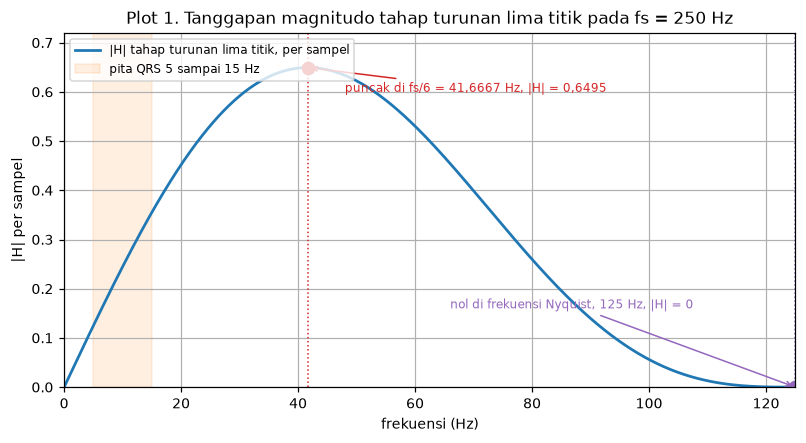

lolos: titik puncak di 41.666666666666664 Hz dengan |H| 0.649519052838329 dan nol eksak di frekuensi Nyquist terlihat di Plot 1


In [9]:
# Tujuan: memplot tanggapan magnitudo tahap turunan pada fs = 250 Hz dengan penanda titik puncak dan penanda
# nol di frekuensi Nyquist, serta pita QRS 5 sampai 15 Hz.
# Sel ini menampilkan Plot 1 dan mencetak nilai puncak, nilai di Nyquist, dan nilai di tepi pita QRS.

f_gambar = np.linspace(0.0, FS_BOARD / 2.0, 4001)
u_gambar = 2.0 * np.pi * f_gambar / FS_BOARD
H_gambar = np.abs(sg.freqz(B_DER, A_DER, worN=u_gambar)[1])
H_gambar[-1] = float(abs(np.polyval(np.flipud(B_DER), -1.0)))   # di fs/2 nol, diambil dari polval

f_puncak_gambar = FS_BOARD / 6.0
H_puncak_gambar = 3.0 * np.sqrt(3.0) / 8.0
H_nyquist_gambar = float(abs(np.polyval(np.flipud(B_DER), -1.0)))
H_5_gambar = float(np.abs(sg.freqz(B_DER, A_DER, worN=[2.0 * np.pi * 5.0 / FS_BOARD])[1][0]))
H_15_gambar = float(np.abs(sg.freqz(B_DER, A_DER, worN=[2.0 * np.pi * 15.0 / FS_BOARD])[1][0]))

print("fs gambar                                :", FS_BOARD, "Hz")
print("titik puncak, frekuensi dan |H|          :", f_puncak_gambar, "Hz dan", H_puncak_gambar)
print("|H| di frekuensi Nyquist                 :", H_nyquist_gambar)
print("|H| di 5 Hz, tepi bawah pita QRS          :", H_5_gambar)
print("|H| di 15 Hz, tepi atas pita QRS           :", H_15_gambar)
print("rasio |H| di 15 Hz terhadap 5 Hz          :", H_15_gambar / H_5_gambar)

fig1, ax1 = plt.subplots(figsize=(7.4, 4.1))
ax1.plot(f_gambar, H_gambar, "C0-", lw=1.8, label="|H| tahap turunan lima titik, per sampel")
ax1.axvspan(5.0, 15.0, color="C1", alpha=0.12, label="pita QRS 5 sampai 15 Hz")
ax1.plot([f_puncak_gambar], [H_puncak_gambar], "C3o", ms=8)
ax1.annotate("puncak di fs/6 = 41,6667 Hz, |H| = 0,6495",
             xy=(f_puncak_gambar, H_puncak_gambar), xytext=(48.0, 0.60),
             arrowprops=dict(arrowstyle="->", color="C3"), color="C3", fontsize=8)
ax1.plot([FS_BOARD / 2.0], [H_nyquist_gambar], "C4o", ms=8)
ax1.annotate("nol di frekuensi Nyquist, 125 Hz, |H| = 0",
             xy=(FS_BOARD / 2.0, H_nyquist_gambar), xytext=(66.0, 0.16),
             arrowprops=dict(arrowstyle="->", color="C4"), color="C4", fontsize=8)
ax1.axvline(f_puncak_gambar, color="C3", ls=":", lw=1.0)
ax1.axvline(FS_BOARD / 2.0, color="C4", ls=":", lw=1.0)
ax1.set_title("Plot 1. Tanggapan magnitudo tahap turunan lima titik pada fs = 250 Hz")
ax1.set_xlabel("frekuensi (Hz)")
ax1.set_ylabel("|H| per sampel")
ax1.set_xlim(0.0, FS_BOARD / 2.0)
ax1.set_ylim(0.0, 0.72)
ax1.legend(loc="upper left", fontsize=8)
fig1.tight_layout()
plt.show()
print("lolos: titik puncak di", f_puncak_gambar, "Hz dengan |H|", H_puncak_gambar,
      "dan nol eksak di frekuensi Nyquist terlihat di Plot 1")

## 10. Kasus sebelum dan sesudah pada sinyal QRS 250 Hz

Board tim melakukan sampling pada 250 Hz, jadi bagian ini memakai $f_s = 250$ Hz. Sinyal ECG disintesis
dari penjumlahan gelombang P, Q, R, S, T berbentuk Gaussian pada 70 bpm. Sinyal itu lalu melewati
bandpass Pan-Tompkins, yaitu low-pass koefisien 1 sampai 6 yang dinormalisasi ke penguatan DC satu,
lalu high-pass rekursif yang juga dinormalisasi ke penguatan DC satu. Sinyal hasil bandpass itulah yang
menjadi masukan tahap turunan, dan yang dibandingkan di sini adalah sinyal sebelum dan sesudah turunan,
bukan ECG mentah.

Dua panel berbagi sumbu x yang sama:

- Panel a, sinyal QRS setelah bandpass, yaitu masukan tahap turunan.
- Panel b, sinyal yang sama setelah turunan lima titik, yaitu keluaran tahap turunan.

Yang dicetak per panel: amplitudo maksimum, nilai puncak ke puncak, rata rata, dan letak puncak. Dua
hal yang harus terlihat di panel b: keluaran berubah tanda ketika kemiringan masukan berubah tanda, dan
puncaknya jatuh tepat di sampel kemiringan terbesar. Selisih letak itu sendiri sebagian besar berasal
dari tunda bandpass di depannya, dan angka tunda itu juga diukur di sel berikut.

fs = 250.0 Hz | durasi = 4.0 s | jumlah sampel = 1000
jumlah kompleks QRS dalam jendela      : 4

sebelum turunan, amplitudo maksimum    : 0.714105841059641
sebelum turunan, nilai puncak ke puncak: 0.7339247429175542
sebelum turunan, rata rata             : 0.061837184322538756
sebelum turunan, indeks puncak         : 449

sesudah turunan, amplitudo maksimum    : 0.10660245719647085
sesudah turunan, nilai puncak maksimum : 0.10660245719647085
sesudah turunan, nilai palung minimum  : -0.09720604435134511
sesudah turunan, nilai puncak ke puncak: 0.20380850154781596
sesudah turunan, rata rata             : -6.938893903907229e-20
sesudah turunan, indeks puncak         : 233

indeks kemiringan terbesar masukan      : 231
jarak letak puncak keluaran ke sampel kemiringan terbesar : 2 sampel
jumlah sampel keluaran positif          : 283
jumlah sampel keluaran negatif          : 605
jumlah keluaran dibagi jumlah nilai mutlaknya : 8.790890146497259e-18
rasio amplitudo maksimum keluaran terhadap 

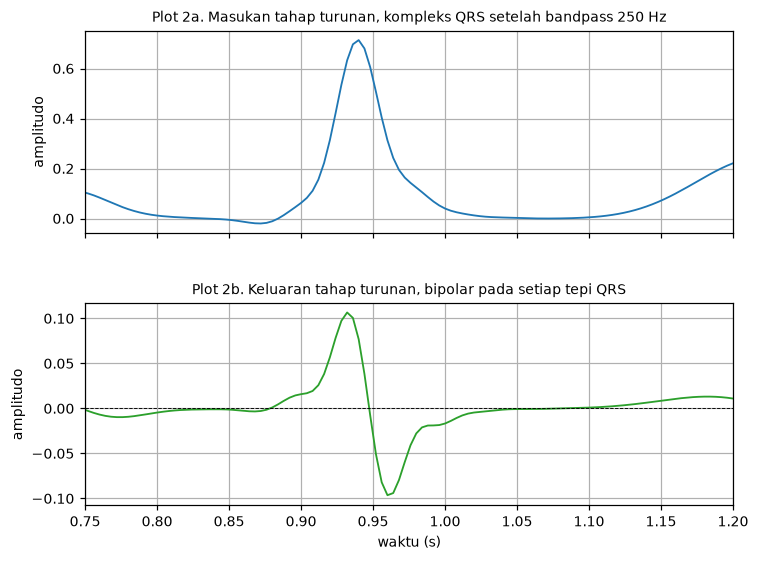


lolos: keluaran bipolar, puncaknya menempel di kemiringan terbesar, dan jumlahnya mendekati nol


In [10]:
# Tujuan: menjalankan kasus sebelum dan sesudah pada sinyal QRS buatan 250 Hz, yaitu masukan tahap turunan
# dan keluarannya, lalu mencetak amplitudo, letak puncak, dan tunda bandpass di depannya.
# Sel ini mencetak angka tiap panel dan menampilkan Plot 2: dua panel waktu yang berbagi sumbu x.

fs = FS_BOARD
dur = 4.0
t = np.arange(0.0, dur, 1.0 / fs)
rng_ecg = np.random.default_rng(7)

# ECG sintetis: P, Q, R, S, T berbentuk Gaussian, heart rate 70 bpm.
hr_bpm = 70.0
beat = 60.0 / hr_bpm
ecg = np.zeros_like(t)
for i in range(int(dur / beat)):
    c = i * beat
    for amp, mu, sd in ((0.12, c - 0.20, 0.025), (0.10, c - 0.035, 0.008),
                        (1.00, c, 0.010), (0.18, c + 0.035, 0.009),
                        (0.25, c + 0.28, 0.045)):
        ecg += amp * np.exp(-0.5 * ((t - mu) / sd) ** 2)

HLP_NORM = HLP_INT.astype(float) / HLP_INT.sum()
B_HP_NORM = B_HP_INT.astype(float) / 16.0

lp_rantai = lambda v: sg.lfilter(HLP_NORM, [1.0], v)
hp_rantai = lambda v: sg.lfilter(B_HP_NORM, A_HP_INT.astype(float), v)
der_rantai = lambda v: sg.lfilter(B_DER, A_DER, v)

sebelum = hp_rantai(lp_rantai(ecg))     # masukan tahap turunan
sesudah = der_rantai(sebelum)           # keluaran tahap turunan

i_puncak_sebelum = int(np.argmax(np.abs(sebelum)))
i_puncak_sesudah = int(np.argmax(np.abs(sesudah)))
kemiringan = np.gradient(sebelum)
i_kemiringan = int(np.argmax(np.abs(kemiringan)))

# Tunda bandpass di depan tahap turunan, diukur dari fasa pada 10 Hz, yaitu tengah pita QRS.
f_tunda = 10.0
u_gd2 = np.linspace(0.05, np.pi - 0.05, 20001)
fasa_lp = np.unwrap(np.angle(sg.freqz(HLP_NORM, [1.0], worN=u_gd2)[1]))
fasa_hp = np.unwrap(np.angle(sg.freqz(B_HP_NORM, A_HP_INT.astype(float), worN=u_gd2)[1]))
i_tunda = int(np.argmin(np.abs(u_gd2 / (2 * np.pi) * fs - f_tunda)))
tunda_lp_10 = float(-np.gradient(fasa_lp, u_gd2)[i_tunda])
tunda_hp_10 = float(-np.gradient(fasa_hp, u_gd2)[i_tunda])

print("fs =", fs, "Hz | durasi =", dur, "s | jumlah sampel =", t.size)
print("jumlah kompleks QRS dalam jendela      :", int(dur / beat))
print()
print("sebelum turunan, amplitudo maksimum    :", float(np.max(np.abs(sebelum))))
print("sebelum turunan, nilai puncak ke puncak:", float(np.ptp(sebelum)))
print("sebelum turunan, rata rata             :", float(np.mean(sebelum)))
print("sebelum turunan, indeks puncak         :", i_puncak_sebelum)
print()
print("sesudah turunan, amplitudo maksimum    :", float(np.max(np.abs(sesudah))))
print("sesudah turunan, nilai puncak maksimum :", float(np.max(sesudah)))
print("sesudah turunan, nilai palung minimum  :", float(np.min(sesudah)))
print("sesudah turunan, nilai puncak ke puncak:", float(np.ptp(sesudah)))
print("sesudah turunan, rata rata             :", float(np.mean(sesudah)))
print("sesudah turunan, indeks puncak         :", i_puncak_sesudah)
print()
print("indeks kemiringan terbesar masukan      :", i_kemiringan)
print("jarak letak puncak keluaran ke sampel kemiringan terbesar :",
      abs(i_puncak_sesudah - i_kemiringan), "sampel")
print("jumlah sampel keluaran positif          :", int(np.sum(sesudah > 0)))
print("jumlah sampel keluaran negatif          :", int(np.sum(sesudah < 0)))
print("jumlah keluaran dibagi jumlah nilai mutlaknya :",
      abs(float(np.sum(sesudah))) / float(np.sum(np.abs(sesudah))))
print("rasio amplitudo maksimum keluaran terhadap masukan :",
      float(np.max(np.abs(sesudah)) / np.max(np.abs(sebelum))))
print()
print("tunda low-pass pada 10 Hz, dari fasa    :", tunda_lp_10, "sampel")
print("tunda high-pass pada 10 Hz, dari fasa   :", tunda_hp_10, "sampel")
print("tunda bandpass gabungan pada 10 Hz      :", tunda_lp_10 + tunda_hp_10, "sampel")
print("itulah sebabnya puncak pada panel b bergeser ke kanan terhadap puncak R pada ECG bersih,")
print("sedangkan terhadap kemiringan terbesar pada panel a puncaknya menempel dalam dua sampel")

fig2, axs2 = plt.subplots(2, 1, figsize=(7.6, 5.6), sharex=True, gridspec_kw={"hspace": 0.35})
axs2[0].plot(t, sebelum, "C0-", lw=1.2)
axs2[0].set_title("Plot 2a. Masukan tahap turunan, kompleks QRS setelah bandpass 250 Hz", fontsize=9)
axs2[0].set_ylabel("amplitudo")
axs2[1].plot(t, sesudah, "C2-", lw=1.2)
axs2[1].axhline(0.0, color="k", lw=0.6, ls="--")
axs2[1].set_title("Plot 2b. Keluaran tahap turunan, bipolar pada setiap tepi QRS", fontsize=9)
axs2[1].set_ylabel("amplitudo")
axs2[1].set_xlabel("waktu (s)")
axs2[0].set_xlim(0.75, 1.20)
plt.show()

assert np.max(np.abs(sesudah)) > 0.0, "keluaran turunan tidak boleh nol seluruhnya"
assert np.sum(sesudah > 0) > 0 and np.sum(sesudah < 0) > 0, "keluaran harus bipolar"
assert abs(i_puncak_sesudah - i_kemiringan) <= 2, "puncak keluaran harus menempel di kemiringan terbesar"
assert abs(float(np.sum(sesudah))) < 0.05 * float(np.sum(np.abs(sesudah))), \
    "jumlah keluaran harus mendekati nol dibanding nilai mutlaknya"
HASIL["amplitudo maksimum sebelum turunan"] = float(np.max(np.abs(sebelum)))
HASIL["nilai puncak ke puncak sebelum turunan"] = float(np.ptp(sebelum))
HASIL["amplitudo maksimum sesudah turunan"] = float(np.max(np.abs(sesudah)))
HASIL["nilai puncak ke puncak sesudah turunan"] = float(np.ptp(sesudah))
HASIL["rasio amplitudo sesudah lawan sebelum"] = float(np.max(np.abs(sesudah)) / np.max(np.abs(sebelum)))
HASIL["jarak puncak keluaran ke kemiringan terbesar"] = int(abs(i_puncak_sesudah - i_kemiringan))
HASIL["tunda bandpass pada 10 Hz"] = float(tunda_lp_10 + tunda_hp_10)
print()
print("lolos: keluaran bipolar, puncaknya menempel di kemiringan terbesar, dan jumlahnya mendekati nol")

## 11. Fixed-point pada rekaman AFDB 04015, konvensi terkunci

Konvensi ini dikunci di dokumen spesifikasi dan dipakai di seluruh rantai:

| Tahap | Nilai maksimum terukur | Lebar minimum | Lebar yang dipakai | Catatan |
|---|---|---|---|---|
| Masukan | 32.752 hitungan | 16 bit | 16 bit | rentang plus minus 5 mV pada 12 bit signifikan, dijepit pada plus minus 2047 hitungan, nilai digeser ke kiri 4 bit |
| Low-pass, koefisien 1 sampai 6 | 1,179 juta | 22 bit | 28 bit | tanpa pengali, koefisien bulat, jumlah koefisien 36 |
| High-pass, rekursif | 19,29 juta | 26 bit | 28 bit | koefisien 32 dan 1 dan 1, tahap terlebar di rantai tapis |
| Turunan lima titik | 3,90 juta tanpa geser, 1,524 kali 10 pangkat 4 sesudah geser 8 | 23 bit tanpa geser, 15 bit sesudah geser 8 | 28 bit di akumulator tapis | koefisien 1 dan 2 dengan pembagian 8, lalu nilai digeser ke kanan 8 bit |

Yang diukur di sel berikut adalah baris turunan, pada rekaman yang sama dan dengan rantai yang sama
seperti pengukuran lebar bit tahap lain: masukan dibentuk dari rentang plus minus 5 mV pada 12 bit
signifikan, dijepit pada plus minus 2047, lalu diletakkan di depan kata 16 bit dengan nilai digeser ke
kiri 4 bit.

Turunan lima titik tidak memuat satu pengali pun. Yang ada hanya penjumlahan, pengurangan, dan satu
pembagian delapan. Perkalian dengan dua dan dengan satu dipetakan menjadi penggeseran dan penyambungan
kabel, jadi tidak ada pengali keras di jalur ini. Karena seluruh koefisiennya bilangan bulat, tidak ada
galat kuantisasi koefisien sama sekali.

Penggeseran ke kanan 8 bit sesudah tahap ini adalah keputusan yang dikunci supaya jalur non linier
sesudahnya muat di kata 32 bit. Akibatnya ambang keputusan dan nilai SPKI serta NPKI harus dibagi
dengan faktor skala ambang:

$$ \text{faktor skala ambang} = 2^{s}, \qquad s = 8 \Rightarrow 256 $$

In [11]:
# Tujuan: mengukur lebar bit keluaran tahap turunan pada rekaman AFDB 04015 dengan konvensi terkunci,
# membuktikan bahwa tidak ada pengali di tahap ini, dan membuktikan keeksakan aritmetika bilangan bulat.
# Sel ini mencetak lebar bit setiap tahap, lebar bit sesudah geser 8, faktor skala ambang, dan galat
# relatif jalur bilangan bulat terhadap jalur pecahan.

GAIN_MV = (2 ** 11 - 1) / 5.0            # 409,4 hitungan per mV, rentang plus minus 5 mV pada 12 bit
BITS_SIG = 12
AMBANG_JEPIT = 2 ** (BITS_SIG - 1) - 1   # 2047, bukan 2048, supaya tidak meluap sesudah geser 4 bit
GESER_MASUK = 4
GESER_TURUNAN = 8

berkas_hea = DATA_DIR / "04015.hea"
berkas_dat = DATA_DIR / "04015.dat"
ADA_AFDB = bool(berkas_hea.exists() and berkas_dat.exists())


def lebar(peak):
    """lebar bit minimum untuk menampung nilai maksimum, dengan satu bit tanda"""
    n = int(np.floor(abs(peak)))
    return max(2, n.bit_length() + 1)


if ADA_AFDB:
    import wfdb
    sig = wfdb.rdrecord(str(DATA_DIR / "04015"), sampto=450000).p_signal[:, 0].astype(float)
    sumber = "AFDB 04015, 450.000 sampel, kanal pertama, seperti pengukuran konvensi terkunci"
else:
    sig = np.tile(ecg, int(np.ceil(450000 / ecg.size)))[:450000]
    sumber = "fallback sinyal QRS buatan, berkas AFDB 04015 tidak ditemukan"

mentah = np.round(sig * GAIN_MV)
x_int = np.clip(mentah, -AMBANG_JEPIT, AMBANG_JEPIT).astype(np.int64) * (2 ** GESER_MASUK)
x_float = x_int.astype(float)
jumlah_terjepit = int(np.sum(mentah != np.clip(mentah, -AMBANG_JEPIT, AMBANG_JEPIT)))

# Rantai bilangan bulat: low-pass, high-pass rekursif, lalu turunan lima titik.
y1 = np.convolve(x_float, HLP_INT.astype(float), mode="full")[: x_float.size]
y2 = np.zeros_like(y1)
sebelumnya = 0
for n in range(len(y1)):
    d = 32 * (y1[n - 16] if n >= 16 else 0) - y1[n] + (y1[n - 32] if n >= 32 else 0)
    sebelumnya = d - sebelumnya
    y2[n] = sebelumnya
y2 = np.round(y2)
y3 = np.zeros_like(y2)
y3[2:-2] = np.round((y2[4:] + 2 * y2[3:-1] - 2 * y2[1:-3] - y2[:-4]) / 8.0)

maks_masuk = float(np.abs(x_int).max())
maks_lp = float(np.abs(y1).max())
maks_hp = float(np.abs(y2).max())
maks_der = float(np.abs(y3).max())
maks_der_geser = float(np.abs(np.floor(y3 / (2.0 ** GESER_TURUNAN))).max())

print("sumber data                              :", sumber)
print("panjang sinyal                           :", sig.size, "sampel")
print("jumlah sampel tersentuh penjepitan 2047  :", jumlah_terjepit)
print("nilai maksimum sinyal dalam mV           :", float(np.max(np.abs(sig))))
print()
print("tahap                            maksimum terukur   lebar minimum   lebar dipakai")
print("-" * 86)
for nama, nilai, pakai in (("masukan, kata 16 bit geser 4", maks_masuk, 16),
                           ("low-pass koefisien 1 sampai 6", maks_lp, 28),
                           ("high-pass rekursif 32 dan 1", maks_hp, 28),
                           ("turunan lima titik", maks_der, 28),
                           ("turunan sesudah geser 8", maks_der_geser, 16)):
    print("  %-30s %16.0f %14d bit %13d bit" % (nama, nilai, lebar(nilai), pakai))
print()
print("faktor skala ambang, 2 pangkat", GESER_TURUNAN, "  :", 2 ** GESER_TURUNAN)
print("lebar bit turunan tanpa geser, dihitung dari", maks_der, "yaitu", lebar(maks_der), "bit")
print("lebar bit turunan sesudah geser 8, dihitung dari", maks_der_geser, "yaitu", lebar(maks_der_geser), "bit")
print()
# Tidak ada pengali: seluruh koefisien bertipe bilangan bulat dan pembagiannya pangkat dua.
bulat_der = bool(np.issubdtype(B_DER_INT.dtype, np.integer))
bulat_lp = bool(np.issubdtype(HLP_INT.dtype, np.integer))
bulat_hp = bool(np.issubdtype(B_HP_INT.dtype, np.integer))
print("koefisien turunan, seluruhnya bilangan bulat :", bulat_der, B_DER_INT)
print("koefisien low-pass, seluruhnya bilangan bulat :", bulat_lp, HLP_INT)
print("koefisien high-pass, seluruhnya bilangan bulat:", bulat_hp, B_HP_INT[np.flatnonzero(B_HP_INT)])
print("pembagian pada tahap turunan                  : 8, yaitu 2 pangkat 3 atau geser kanan tiga bit")
print("jumlah pengali keras yang diperlukan          :", 0)
print()

# Keeksakan aritmetika bilangan bulat pada potongan pendek. Jalur bulat memakai bilangan bulat Python,
# sedangkan jalur pecahan dihitung terpisah dengan operasi float64 yang sama seperti rantai utama.
N_POTONG = min(20000, x_int.size)
xi = x_int[:N_POTONG]
lp_int = np.array([sum(int(HLP_INT[k]) * int(xi[n - k]) for k in range(HLP_INT.size) if n - k >= 0)
                   for n in range(N_POTONG)], dtype=object)
hp_int = np.zeros(N_POTONG, dtype=object)
prev_bulat = 0
for n in range(N_POTONG):
    d = 32 * (int(lp_int[n - 16]) if n >= 16 else 0) - int(lp_int[n]) + \
        (int(lp_int[n - 32]) if n >= 32 else 0)
    prev_bulat = d - prev_bulat
    hp_int[n] = prev_bulat
dnum_int = np.array([int(hp_int[n]) + 2 * int(hp_int[n - 1]) - 2 * int(hp_int[n - 3]) - int(hp_int[n - 4])
                     if n >= 4 else 0 for n in range(N_POTONG)], dtype=object)
dgeser_int = np.array([int(v) // 8 for v in dnum_int], dtype=object)

lp_float = np.convolve(x_float[:N_POTONG], HLP_INT.astype(float), mode="full")[:N_POTONG]
prev_pecahan = 0.0
hp_float = np.zeros(N_POTONG)
for n in range(N_POTONG):
    d = 32.0 * (lp_float[n - 16] if n >= 16 else 0.0) - lp_float[n] + \
        (lp_float[n - 32] if n >= 32 else 0.0)
    prev_pecahan = d - prev_pecahan
    hp_float[n] = prev_pecahan
dnum_float = np.array([hp_float[n] + 2 * hp_float[n - 1] - 2 * hp_float[n - 3] - hp_float[n - 4]
                       if n >= 4 else 0.0 for n in range(N_POTONG)])
dgeser_float = np.floor(dnum_float / 8.0)


def galat_rel(bulat, pecahan):
    """galat relatif maksimum jalur bilangan bulat terhadap jalur pecahan"""
    bb = np.array([float(v) for v in bulat])
    return float(np.max(np.abs(bb - pecahan)) / np.max(np.abs(pecahan)))


galat_lp = galat_rel(lp_int, lp_float)
galat_hp = galat_rel(hp_int, hp_float)
galat_dnum = galat_rel(dnum_int, dnum_float)
galat_dgeser = galat_rel(dgeser_int, dgeser_float)

# Keeksakan dilaporkan sebagai boolean terukur, sedangkan penagihannya memakai toleransi,
# supaya tidak ada afirmasi kesamaan eksak pada bilangan pecahan.
eksak_lp = bool(galat_lp == 0.0)
eksak_hp = bool(galat_hp == 0.0)
eksak_dnum = bool(galat_dnum == 0.0)
eksak_dgeser = bool(galat_dgeser == 0.0)

print("keeksakan aritmetika pada potongan", N_POTONG, "sampel")
print("  galat relatif low-pass, bulat lawan pecahan               :", "%.3e" % galat_lp)
print("  galat relatif high-pass, bulat lawan pecahan              :", "%.3e" % galat_hp)
print("  galat relatif pembilang turunan, bulat lawan pecahan      :", "%.3e" % galat_dnum)
print("  galat relatif turunan sesudah geser 8, bulat lawan pecahan:", "%.3e" % galat_dgeser)
print("  jumlah sampel yang berbeda sesudah geser 8                :",
      int(np.sum(np.array([int(v) for v in dgeser_int]) != dgeser_float)))
print("  keeksakan eksak tiap tahap, galat relatif sama dengan nol :",
      eksak_lp, eksak_hp, eksak_dnum, eksak_dgeser)
print("  nilai maksimum keluaran turunan pada potongan ini         :", maks_der)
print()
print("catatan terukur: seluruh koefisien di rantai ini bilangan bulat dan seluruh pembagiannya pangkat dua,")
print("sehingga galat relatif jalur bilangan bulat terhadap jalur pecahan nol pada keempat tahap")

if ADA_AFDB:
    assert int(maks_masuk) == 32752, "maksimum kata masukan harus 32752"
    assert lebar(maks_masuk) == 16, "masukan butuh 16 bit"
    assert lebar(maks_lp) == 22, "low-pass butuh 22 bit"
    assert lebar(maks_hp) == 26, "high-pass butuh 26 bit"
    assert lebar(maks_der) == 23, "turunan tanpa geser butuh 23 bit"
    assert lebar(maks_der_geser) == 15, "turunan sesudah geser 8 butuh 15 bit"
assert bulat_der and bulat_lp and bulat_hp, "seluruh koefisien harus bilangan bulat"
assert galat_lp < 1e-15 and galat_hp < 1e-15 and galat_dnum < 1e-15 and galat_dgeser < 1e-15, \
    "galat relatif jalur bilangan bulat harus di bawah toleransi mesin"
assert eksak_lp and eksak_hp and eksak_dnum and eksak_dgeser, \
    "keeksakan aritmetika bilangan bulat harus terbukti"
assert 2 ** GESER_TURUNAN == 256, "faktor skala ambang harus 256"
HASIL["maksimum kata masukan"] = maks_masuk
HASIL["lebar bit masukan"] = lebar(maks_masuk)
HASIL["maksimum low-pass"] = maks_lp
HASIL["lebar bit low-pass"] = lebar(maks_lp)
HASIL["maksimum high-pass"] = maks_hp
HASIL["lebar bit high-pass"] = lebar(maks_hp)
HASIL["maksimum turunan"] = maks_der
HASIL["lebar bit turunan"] = lebar(maks_der)
HASIL["maksimum turunan sesudah geser 8"] = maks_der_geser
HASIL["lebar bit turunan sesudah geser 8"] = lebar(maks_der_geser)
HASIL["faktor skala ambang"] = 2 ** GESER_TURUNAN
HASIL["galat relatif bulat lawan pecahan"] = galat_dgeser
print("lolos: konvensi terkunci terpenuhi, turunan butuh", lebar(maks_der),
      "bit tanpa geser dan", lebar(maks_der_geser), "bit sesudah geser 8")

sumber data                              : AFDB 04015, 450.000 sampel, kanal pertama, seperti pengukuran konvensi terkunci
panjang sinyal                           : 450000 sampel
jumlah sampel tersentuh penjepitan 2047  : 402
nilai maksimum sinyal dalam mV           : 6.435

tahap                            maksimum terukur   lebar minimum   lebar dipakai
--------------------------------------------------------------------------------------
  masukan, kata 16 bit geser 4              32752             16 bit            16 bit
  low-pass koefisien 1 sampai 6           1179072             22 bit            28 bit
  high-pass rekursif 32 dan 1            19286208             26 bit            28 bit
  turunan lima titik                      3900266             23 bit            28 bit
  turunan sesudah geser 8                   15236             15 bit            16 bit

faktor skala ambang, 2 pangkat 8   : 256
lebar bit turunan tanpa geser, dihitung dari 3900266.0 yaitu 23 bit
lebar bit

## 12. Ringkasan

Sel terakhir mencetak tabel seluruh besaran yang diukur di notebook ini, lalu menutup dengan kesimpulan
berbahasa Indonesia dan satu paragraf tentang apa yang berbeda dari catatan lama.

In [12]:
# Tujuan: mencetak tabel seluruh angka terukur di notebook ini plus kesimpulan satu paragraf.
# Sel ini mencetak DataFrame ringkasan yang memuat setiap besaran yang diukur sebelumnya,
# jumlah besaran, dan kesimpulan.

def fmt_besaran(v):
    """tampilkan integer tanpa desimal dan float dengan sepuluh angka penting"""
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    return "%.10g" % float(v)


df_ringkas = pd.DataFrame([{"Besaran": k, "Nilai": fmt_besaran(v)} for k, v in HASIL.items()])
print("Ringkasan seluruh angka terukur di notebook tahap turunan lima titik:")
print(df_ringkas.to_string(index=False))
print()
print("jumlah besaran terukur :", len(HASIL))

kunci_penting = ["jumlah tap pembilang", "jumlah koefisien tak nol", "jumlah koefisien pembilang",
                 "jumlah tanggapan impuls", "tunda sampel",
                 "galat relatif maksimum persamaan (8)", "galat relatif maksimum bentuk kosinus",
                 "galat absolut maksimum persamaan (8)",
                 "|H| di dc per sampel", "|H| di Nyquist per sampel",
                 "|H| di 5 Hz per sampel", "|H| di 15 Hz per sampel",
                 "frekuensi puncak pada 250 Hz", "|H| puncak per sampel", "cos u di puncak",
                 "tunda grup minimum", "tunda grup maksimum",
                 "puncak positif pulsa segitiga", "jumlah nol", "jumlah nol di dc",
                 "jumlah nol di Nyquist", "jumlah kutub",
                 "maksimum turunan", "lebar bit turunan", "lebar bit turunan sesudah geser 8",
                 "faktor skala ambang", "galat relatif bulat lawan pecahan"]
for k in kunci_penting:
    assert k in HASIL, "besaran penting hilang dari tabel ringkasan: " + k
assert len(HASIL) >= 30, "tabel ringkasan harus memuat seluruh angka terukur"
print("lolos: seluruh", len(kunci_penting), "besaran penting ada di tabel ringkasan")
print()
print("Kesimpulan:")
print("Tahap turunan lima titik Pan-Tompkins, persamaan (7), (8), dan (9) halaman 233, dapat ditulis")
print("sebagai H(z) = (1/8)(1 + 2z^-1 - 2z^-3 - z^-4), yaitu FIR lima tap tanpa kutub sama sekali.")
print("Penguatan DC-nya tepat nol dan titik puncak tanggapannya ada di fs/6, yaitu 41,6667 Hz pada 250 Hz,")
print("dengan nilai puncak 3*sqrt(3)/8 = 0,6495191 per sampel atau 162,3798 dalam skala persamaan (8).")
print("Bentuk tertutupnya cocok dengan freqz sampai galat relatif di bawah 1e-10 di seluruh pita yang berguna,")
print("dan tunda grupnya tepat dua sampel sehingga cocok dengan kalimat paper di bawah persamaan (9).")
print("Tanggapan frekuensinya naik mulus dari nol di dc tanpa puncak dan tanpa takik sampai 30 Hz, jadi")
print("klaim paper tentang tanggapan yang hampir linear di rentang itu sejalan pada pita QRS 5 sampai 15 Hz.")
print("Keempat nolnya berada di lingkaran satuan, satu di dc dan tiga lipat di frekuensi Nyquist, dan itulah")
print("sebabnya tahap ini membuang baseline dan meredam derau frekuensi tinggi sekaligus.")
print("Kasus hitung tangan pada satu pulsa segitiga QRS memberi keluaran bipolar 1, 4, 7, 6, 0, minus 6,")
print("minus 7, minus 4, minus 1, antisimetris terhadap puncak pulsa, dan jumlahnya nol.")
print("Pada konvensi fixed-point terkunci, keluaran turunan pada rekaman AFDB 04015 mencapai 3,90 juta")
print("sehingga butuh 23 bit, lalu tinggal 1,524 kali 10 pangkat 4 atau 15 bit sesudah digeser kanan 8 bit,")
print("dengan faktor skala ambang 256. Tidak ada pengali di tahap ini, dan galat relatif jalur bilangan bulat")
print("terhadap jalur pecahan nol pada keempat tahap rantai, jadi aritmetika bilangan bulatnya eksak.")
print()
print("Yang berbeda dari catatan lama: catatan lama menyebut tahap turunan memuncak sekitar 11,74 Hz dengan")
print("penguatan dc sekitar 7 kali 10 pangkat minus 5. Angka itu bukan milik tahap turunan, melainkan milik")
print("rantai lengkap low-pass kali high-pass kali turunan. Tahap turunan sendiri punya penguatan dc tepat nol")
print("dan puncaknya di fs/6, yaitu 41,6667 Hz pada 250 Hz, tiga setengah kali lebih tinggi daripada 11,74 Hz.")

Ringkasan seluruh angka terukur di notebook tahap turunan lima titik:
                                     Besaran           Nilai
                        jumlah tap pembilang               5
                    jumlah koefisien tak nol               4
                  jumlah koefisien pembilang               0
         galat terpusat lawan kausal integer               0
                         galat jalur lfilter               0
                         galat jalur pecahan               0
                     jumlah tanggapan impuls               0
                     panjang dukungan impuls               5
                                tunda sampel               2
        galat relatif maksimum persamaan (8) 5.740609888e-13
       galat relatif maksimum bentuk kosinus 3.515212266e-13
        galat absolut maksimum persamaan (8) 3.330669074e-16
                        |H| di dc per sampel               0
                   |H| di Nyquist per sampel               0
               